# 02 · 文本模型对比 Text models compared

**Data Science Club · BIPH FindMy**

匹配引擎要判断两段描述说的是不是同一件东西，而且常常一段是中文、一段是英文。我们比较三种把文字变成可比较向量的方法：

| 方法 | 原理 | 大小 |
|---|---|---|
| **TF‑IDF**（字符 n‑gram） | 数共同的字词片段，越少见的片段权重越高 | 0 MB |
| **MiniLM**（`paraphrase-multilingual-MiniLM-L12-v2`，int8） | 多语言句向量模型：意思相近的句子向量也相近，中英文之间也一样 | 118 MB |
| **e5-small**（`multilingual-e5-small`，int8） | 另一种多语言句向量模型，训练方式不同 | 118 MB |

评判标准：**只看描述文字**，能不能把正确的捡到物品排第一？速度和体积能不能放进 Vercel 函数（上限 500 MB，冷启动越快越好）？

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "matcher").is_dir():  # works from the repo root or from matcher/notebooks
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INDIGO, CYAN, MUTED, INK, ORANGE = "#3b3fb6", "#2bb5c4", "#9aa0b4", "#1d1f2e", "#c2410c"
plt.rcParams.update({
    "font.family": ["Noto Sans CJK SC", "DejaVu Sans"],  # Chinese labels need a CJK font
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
})
pd.set_option("display.max_colwidth", 70)

In [2]:
import time
import httpx
from matcher.embed import OnnxEmbedder, load_embedder

# multilingual-e5-small (int8 ONNX export by Xenova), pinned to one revision
E5_REPO, E5_REV = "Xenova/multilingual-e5-small", "761b726dd34fb83930e26aab4e9ac3899aa1fa78"
E5_DIR = ROOT / "matcher" / "models" / "multilingual-e5-small"
E5_DIR.mkdir(parents=True, exist_ok=True)
endpoint = os.environ.get("HF_ENDPOINT", "https://huggingface.co")  # hf-mirror.com from mainland China
for remote, local in (("onnx/model_quantized.onnx", "model.onnx"), ("tokenizer.json", "tokenizer.json")):
    dest = E5_DIR / local
    if not dest.exists():
        with httpx.stream("GET", f"{endpoint}/{E5_REPO}/resolve/{E5_REV}/{remote}", follow_redirects=True,
                          timeout=120) as resp:
            resp.raise_for_status()
            with open(dest, "wb") as fh:
                for chunk in resp.iter_bytes(1 << 20):
                    fh.write(chunk)
    print(f"{local}: {dest.stat().st_size / 1e6:.0f} MB")

minilm = load_embedder()
assert minilm is not None, "run `make model` first"


class E5:
    """e5 is trained with prefixes: 'query: ' for what you search with, 'passage: ' for what is searched.
    (We also tried 'query: ' on both sides; it was worse.)"""

    def __init__(self, path):
        self.inner = OnnxEmbedder(path)

    def encode(self, texts, prefix="query: ", batch_size=32):
        return self.inner.encode([prefix + t for t in texts], batch_size)


e5 = E5(E5_DIR)

model.onnx: 118 MB
tokenizer.json: 17 MB


## 1. 跨语言：中文和英文描述能对上吗？ · Cross-lingual similarity

左边 3 条是失主写的中文丢失描述，上面 6 条是捡到描述（大多是英文，有几个是"撞款"）。每一行里颜色最深的格子，就是该模型认为最像的那一条。

注意：不同模型的相似度**数值不能直接比较**（e5 的相似度普遍偏高），要看的是**每一行里的排序**对不对。

F1: black thermos bottle with a green dinosaur sticker
F2: black Hydro Flask, dented near the bottom
F3: white AirPods case, J.W. engraved on the back
F4: white earbuds case with a cat silicone cover
F5: navy Nike hoodie, size M, changing room
F6: dark blue sweatshirt, no logo


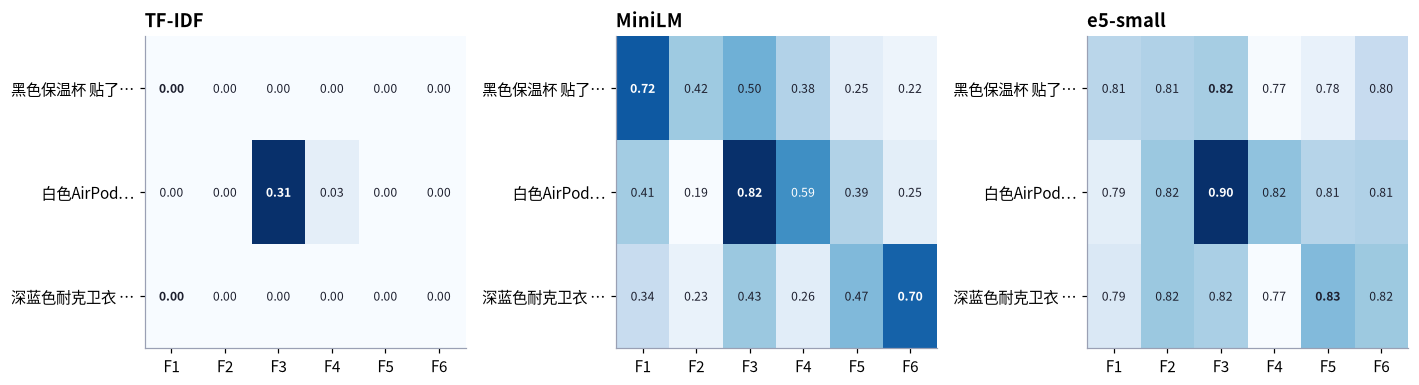

In [3]:
from matcher.api import ItemInput, Matcher
from matcher.textsim import Tfidf
from datetime import datetime, timezone

lost = ["黑色保温杯 贴了恐龙贴纸", "白色AirPods耳机盒 背面刻了J.W.", "深蓝色耐克卫衣 M码"]
found = ["black thermos bottle with a green dinosaur sticker", "black Hydro Flask, dented near the bottom",
         "white AirPods case, J.W. engraved on the back", "white earbuds case with a cat silicone cover",
         "navy Nike hoodie, size M, changing room", "dark blue sweatshirt, no logo"]

tf = Matcher(backend="tfidf")
now = datetime.now(timezone.utc)
def tf_vec(text):
    return tf.prepare(ItemInput(text, "lost", text, now)).tf_text

sims = {
    "TF-IDF": np.array([[Tfidf.cosine(tf_vec(a), tf_vec(b)) for b in found] for a in lost]),
    "MiniLM": minilm.encode(lost) @ minilm.encode(found).T,
    "e5-small": e5.encode(lost, "query: ") @ e5.encode(found, "passage: ").T,
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, m) in zip(axes, sims.items()):
    ax.imshow(m, cmap="Blues", aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if m[i, j] > m.min() + 0.6 * (m.max() - m.min()) else INK,
                    fontweight="bold" if j == m[i].argmax() else "normal")
    ax.set_xticks(range(len(found)), [f"F{j + 1}" for j in range(len(found))])
    ax.set_yticks(range(len(lost)), [s[:8] + "…" for s in lost])
    ax.set_title(name, loc="left", fontweight="bold")
fig.tight_layout()
for j, s in enumerate(found):
    print(f"F{j + 1}: {s}")

## 2. 只看文字的检索效果 · Text-only retrieval

和评估报告用同样的规则：每条丢失描述去所有"时间上可能"的捡到描述里找（比丢失时间早一天以上被捡到的直接排除），看正确答案排在第几。
**这里只用文字**，类别、颜色、地点、时间都不参与，所以测的纯粹是文本模型本身。

In [4]:
from matcher.eval.common import metrics, ranks_from_scores
from matcher.eval.datasets import load_handwritten
from matcher.eval.run import Evaluator, synthetic_test
from matcher.extract import extract
from matcher.vocab import load_vocab

vocab = load_vocab()

def text_only(eval_set):
    """R@k for each encoder on the same time-gated candidate pairs."""
    ev = Evaluator(eval_set)
    table = ev.table("tfidf")                # candidate pairs that survive the time gate
    order = [q.id for q in eval_set.queries]
    texts = {r.id: extract(r.to_item().public_text, vocab).text or " " for r in eval_set.queries + eval_set.pool}
    # TF-IDF and MiniLM: the matcher's own text feature (identical to the evaluation report)
    out = {"TF-IDF": ev.ranks("tfidf", lambda x: x[0]), "MiniLM": ev.ranks("onnx", lambda x: x[0])}
    # e5: same candidate pairs, scored with e5 vectors
    qids, cids = order, [c.id for c in eval_set.pool]
    qv = dict(zip(qids, e5.encode([texts[i] for i in qids], "query: ")))
    cv = dict(zip(cids, e5.encode([texts[i] for i in cids], "passage: ")))
    scores = np.array([float(qv[q] @ cv[c]) for q, c in zip(table.qids, table.cids)])
    out["e5-small"] = ranks_from_scores(table, scores, ev.truth, order, np.random.default_rng(0))
    return out, ev

syn_set, _ = synthetic_test(900)
syn_ranks, syn_ev = text_only(syn_set)
hw_ranks, _ = text_only(load_handwritten())

table = pd.DataFrame({(set_name, k): {name: 100 * metrics(r)[k] if k != "MRR" else metrics(r)[k]
                                       for name, r in ranks.items()}
                      for set_name, ranks in (("synthetic", syn_ranks), ("hand-written", hw_ranks))
                      for k in ("R@1", "R@3", "MRR")}).round(2)
table

synthetic              hand-written             
               R@1    R@3   MRR          R@1    R@3   MRR
TF-IDF       28.87  39.18  0.37        18.75  34.38  0.29
MiniLM       38.14  58.76  0.52        84.38  93.75  0.90
e5-small     34.02  37.11  0.38        21.88  40.62  0.36

### 跨语言 vs 同语言 · Cross-language vs same-language pairs

最能说明问题的是：失主用中文写、捡到者用英文写（或者反过来）的时候，各个模型还行不行？

,TF-IDF,MiniLM,e5-small
text-only R@1 (%),,,
same language,62.9,57.1,85.7
cross-language (中 ↔ EN),2.9,28.6,0.0
mixed,18.5,25.9,11.1


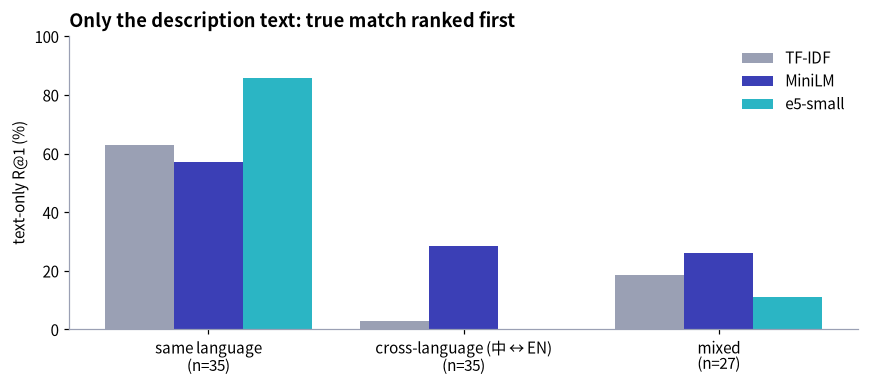

In [5]:
zh = {"zh", "zh-hant"}
by_id = {r.id: r for r in syn_set.queries + syn_set.pool}
truth = syn_ev.truth
queries_with_truth = [q.id for q in syn_set.queries if q.id in truth]

def group(qid):
    a, b = by_id[qid].lang, by_id[truth[qid]].lang
    if "mixed" in (a, b):
        return "mixed"
    return "same language" if (a in zh) == (b in zh) else "cross-language (中 ↔ EN)"

groups = [group(q) for q in queries_with_truth]
names = ["same language", "cross-language (中 ↔ EN)", "mixed"]
by_group = pd.DataFrame({enc: [100 * np.mean([(r is not None and r <= 1) for r, g in zip(syn_ranks[enc], groups)
                                              if g == name]) for name in names]
                         for enc in ("TF-IDF", "MiniLM", "e5-small")}, index=names).round(1)
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (enc, color) in enumerate((("TF-IDF", MUTED), ("MiniLM", INDIGO), ("e5-small", CYAN))):
    ax.bar(np.arange(3) + (k - 1) * 0.27, by_group[enc], 0.27, color=color, label=enc)
ax.set_xticks(range(3), [f"{n}\n(n={groups.count(n)})" for n in names])
ax.set_ylabel("text-only R@1 (%)")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
ax.set_title("Only the description text: true match ranked first", loc="left", fontweight="bold")
fig.tight_layout()
by_group.rename_axis("text-only R@1 (%)")

## 3. 速度和体积 · Speed and size

线上服务跑在 Vercel 的 Python 函数里（2 核 CPU）。模型要和代码一起打包，冷启动时还要加载，所以体积和速度跟准确率一样重要。

In [6]:
import statistics

def bench(name, enc, model_path, load):
    t0 = time.perf_counter()
    load()
    load_s = time.perf_counter() - t0
    sents = [f"black water bottle number {i} with a sticker 黑色水杯 {i}" for i in range(64)]
    single = []
    for i in range(20):
        t = time.perf_counter()
        enc.encode([f"lost my calculator {i} 计算器"])
        single.append((time.perf_counter() - t) * 1000)
    t = time.perf_counter()
    enc.encode(sents)
    batch = (time.perf_counter() - t) * 1000 / len(sents)
    return {"model": name, "file (MB)": round(model_path.stat().st_size / 1e6),
            "load (s)": round(load_s, 2), "1 sentence (ms)": round(statistics.median(single), 1),
            "per sentence in a batch of 64 (ms)": round(batch, 1)}

mini_dir = ROOT / "matcher" / "models" / "paraphrase-multilingual-MiniLM-L12-v2"
rows = [
    bench("MiniLM", minilm, mini_dir / "model.onnx", lambda: OnnxEmbedder(mini_dir)),
    bench("e5-small", e5, E5_DIR / "model.onnx", lambda: OnnxEmbedder(E5_DIR)),
]
pd.DataFrame(rows).set_index("model")

,file (MB),load (s),1 sentence (ms),per sentence in a batch of 64 (ms)
model,,,,
MiniLM,118,1.57,5.0,2.4
e5-small,118,1.39,3.6,1.9


## 结论 · Takeaways

- **跨语言能力决定了选 MiniLM**：失主写中文、捡到者写英文（或者反过来）时，只看文字的 R@1：TF‑IDF 3%，e5-small 0%，MiniLM 29%。MiniLM（paraphrase-multilingual）是用翻译句对训练的，意思相同的中文句子和英文句子会被放到相近的位置；e5 没有专门做这一步，所以中英文之间几乎对不上。我们核对过，这不是 int8 量化造成的：fp32 原版模型的结果一样；把前缀换成 query/query 也不行。
- **同语言时 e5 更强**：两段描述是同一种语言时，e5 的 R@1 是 86%，MiniLM 是 57%。不过在我们学校，中英文混着写是常态，跨语言能力更重要。
- **手写数据**：只看文字时，MiniLM 把 84% 的正确物品排在第一，TF‑IDF 是 19%，e5 是 22%。
- **只看文字不够**：在合成数据上，即使是 MiniLM，纯文字的 R@1 也只有 38%。完整模型再加上类别、颜色、地点、时间和特征标记，R@1 达到 89%（见[评估报告](../../docs/eval_report.md)）。
- **成本相同**：两个模型都是 118 MB，加载约 2 秒，单句编码约 5 毫秒，都放得进 Vercel 函数。所以选 **MiniLM**。
- **Q2 可以试**：按语言组合融合两个模型（同语言用 e5，跨语言用 MiniLM），或者试更大的 `multilingual-e5-base`、`bge-m3`。代价是函数包更大、冷启动更慢。